Bike Sharing Demand

Dataset Description

See, fork, and run a random forest benchmark model through Kaggle Scripts

You are provided hourly rental data spanning two years. For this competition, the training set is comprised of the first 19 days of each month, while the test set is the 20th to the end of the month. You must predict the total count of bikes rented during each hour covered by the test set, using only information available prior to the rental period.

Data Fields

datetime - hourly date + timestamp  \
season -  1 = spring, 2 = summer, 3 = fall, 4 = winter \
holiday - whether the day is considered a holiday\
workingday - whether the day is neither a weekend nor holiday\
weather - 1: Clear, Few clouds, Partly cloudy, Partly cloudy\
2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist\
3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds\
4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog \
temp - temperature in Celsius\
atemp - "feels like" temperature in Celsius\
humidity - relative humidity\
windspeed - wind speed\
casual - number of non-registered user rentals initiated\
registered - number of registered user rentals initiated\
count - number of total rentals


In [6]:
# Instalar las librerias necesarias
%pip install missingno

  Using cached missingno-0.5.2-py3-none-any.whl.metadata (639 bytes)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached missingno-0.5.2-py3-none-any.whl (8.7 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [17]:
# Importar librerias
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import missingno as msno
from sklearn.model_selection import train_test_split
import mlflow
import mlflow.sklearn
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

In [3]:
path = "../../data/"
data = pd.read_csv(path+"train.csv")
data.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [4]:
# Check for missing values
missing_values = data.isnull().sum()
print(missing_values)

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64


<Axes: >

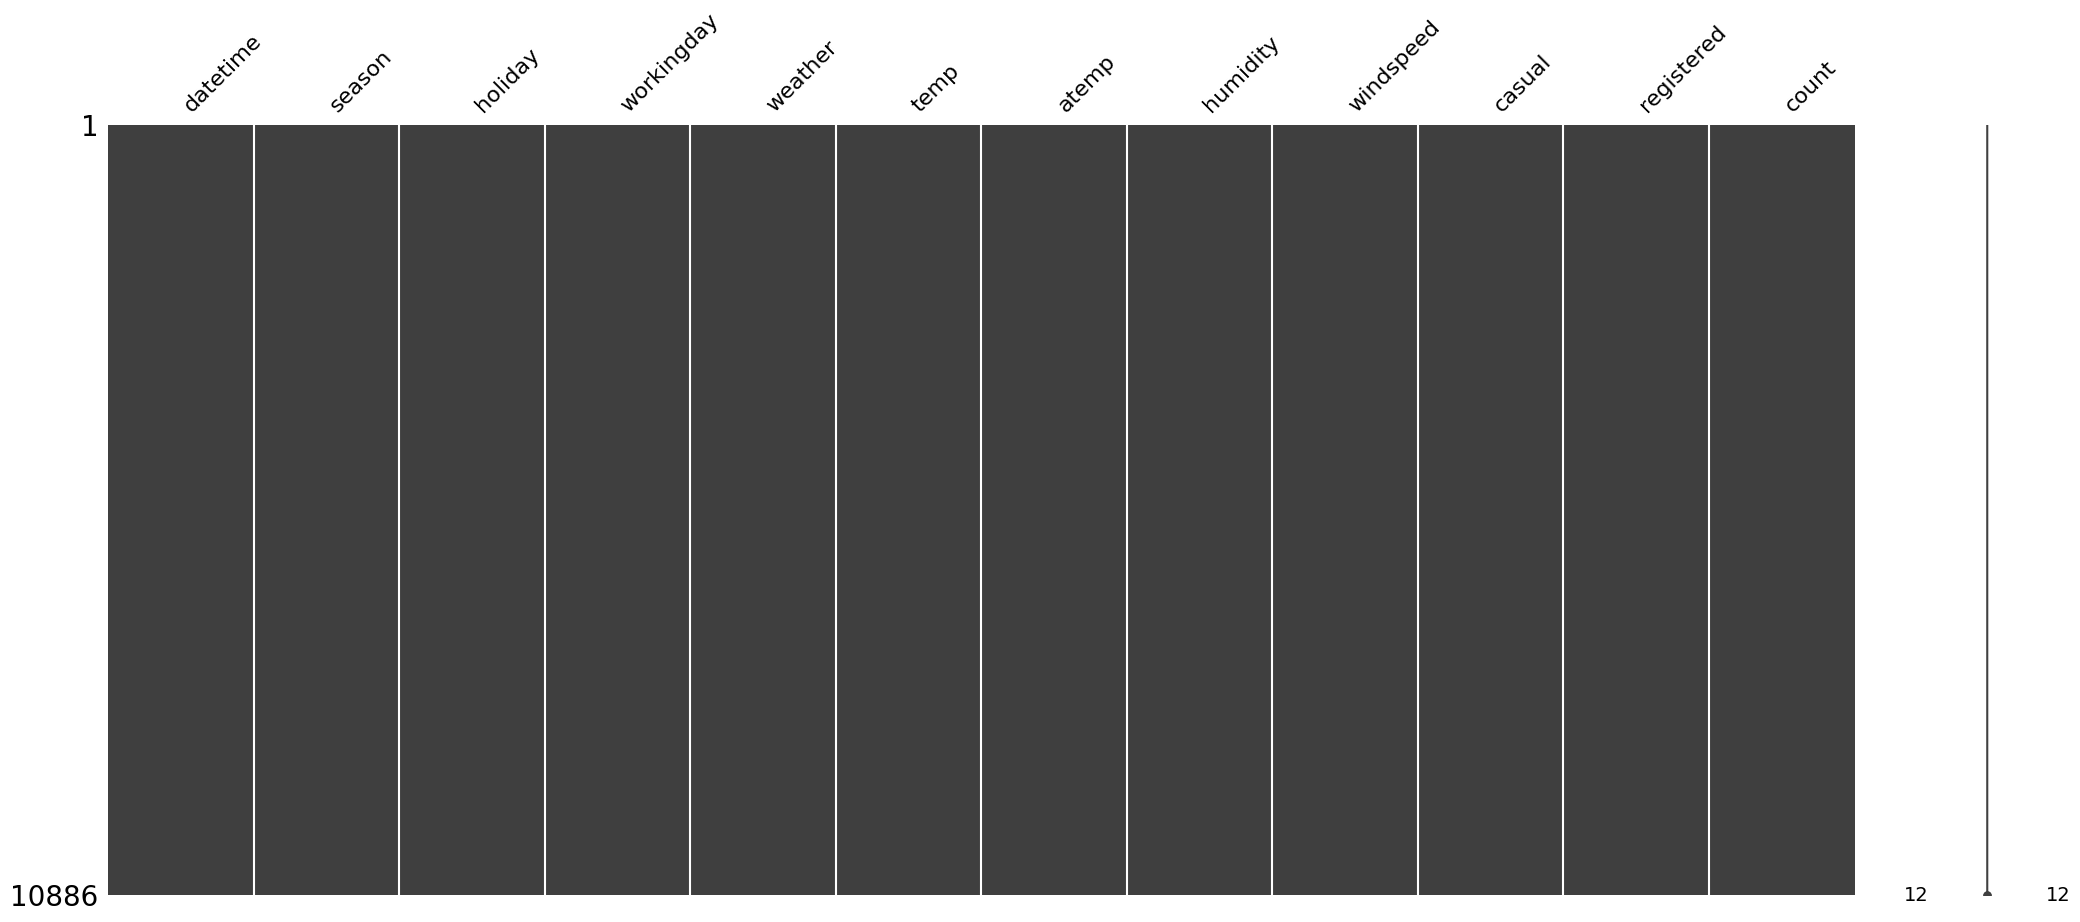

In [8]:
# verificar completitud de los datos
msno.matrix(data)

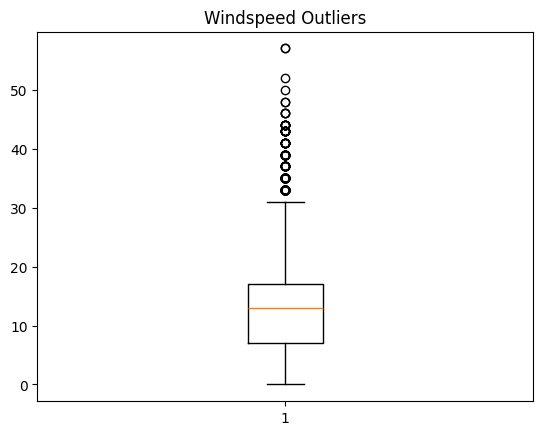

In [9]:
# Box plot to detect outliers in windspeed
plt.boxplot(data['windspeed'])
plt.title('Windspeed Outliers')
plt.show()
# Cap windspeed at a maximum threshold if necessary
data['windspeed'] = data['windspeed'].clip(upper=40)

In [10]:
# Remove rows with negative or erroneous values
data = data[data['temp'] >= 0]

In [11]:
# Convert 'datetime' column to datetime object
data['datetime'] = pd.to_datetime(data['datetime'])

In [12]:
# Create binary weather features
data['is_clear_weather'] = (data['weather'] == 1).astype(int)
data['is_rainy_weather'] = (data['weather'] >= 3).astype(int)

In [13]:
# Create a combined feature for holidays and working days
data['is_holiday_workingday'] = ((data['holiday'] == 1) & (data['workingday'] == 1)).astype(int)

In [14]:
data.drop(columns=["datetime"], inplace=True)

In [16]:
# Split the data into features and target
X = data.drop(columns=["count"])  # Features (all columns except 'count')
y = data["count"]  # Target variable
# Perform an 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Verify the split
print(f"Training data size: {X_train.shape}")
print(f"Testing data size: {X_test.shape}")

Training data size: (8708, 13)
Testing data size: (2178, 13)


#  Model Training with MLFlow Tracking

2025/03/19 21:11:50 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Model training complete. MAE: 3.4106210713492375, RMSE: 5.845038751376032


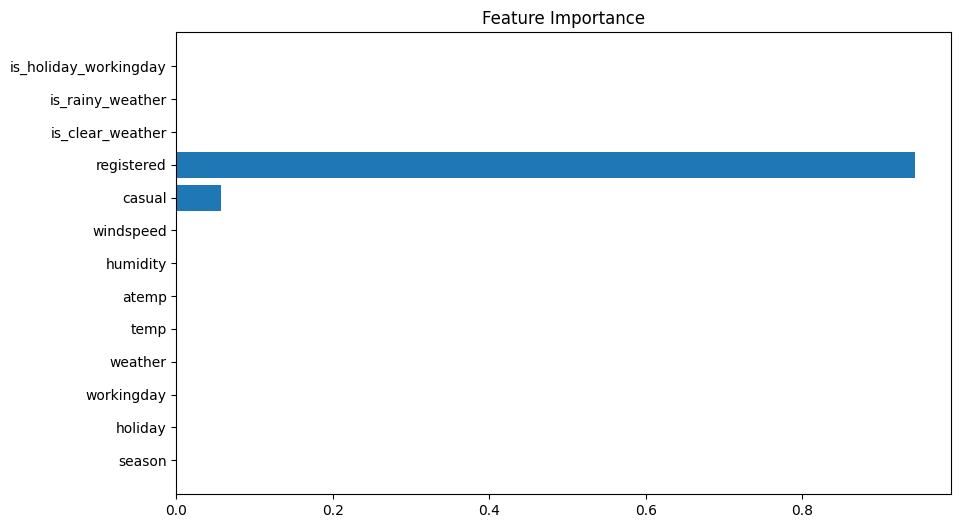

In [18]:
# Define the model
model = DecisionTreeRegressor(max_depth=10, random_state=42)
# Start an MLFlow run
with mlflow.start_run():
    # Log model parameters
    mlflow.log_param("model_type", "DecisionTreeRegressor")
    mlflow.log_param("max_depth", 10)
    
    # Train the model
    model.fit(X_train, y_train)
    
    # Make predictions on the test set
    predictions = model.predict(X_test)
    
    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    
    # Log evaluation metrics
    mlflow.log_metric("MAE", mae)
    mlflow.log_metric("RMSE", rmse)
    
    # Plot and log feature importance as an artifact
    feature_importances = model.feature_importances_
    plt.figure(figsize=(10, 6))
    plt.barh(X_train.columns, feature_importances)
    plt.title("Feature Importance")
    plt.savefig("feature_importance.png")
    
    # Log the artifact (the feature importance plot)
    mlflow.log_artifact("feature_importance.png")
    
    # Log the model itself
    mlflow.sklearn.log_model(model, "model")
    
print(f"Model training complete. MAE: {mae}, RMSE: {rmse}")

In [19]:
mlflow.log_param("max_depth", 10)

10

In [20]:
mlflow.log_metric("MAE", mae) 
mlflow.log_metric("RMSE", rmse)

In [21]:
plt.savefig("feature_importance.png")
mlflow.log_artifact("feature_importance.png")

<Figure size 640x480 with 0 Axes>

In [ ]:
mlflow.sklearn.log_model(model, "model")